# Stage 5: XGBoost Forecasting
## Hospital Resource Intelligence and Optimization Platform

This notebook implements and evaluates the **XGBoost (Extreme Gradient Boosting)** time-series forecasting model. The model is a supervised machine-learning model that uses lagged values, rolling statistics, and calendar features to predict hospital demand for the next **7 days**.

The forecasting pipeline consists of:
1. **Chronological Splitting**: Splitting our 152 rows of feature data into a training set (first 145 rows) and a test set (last 7 rows).
2. **Supervised Regression**: Fitting `xgb.XGBRegressor` on training columns.
3. **Forecast Generation**: Generating predictions for the 7-day test window.
4. **Feature Importance**: Visualizing global feature contributions to understand which lags or rolling windows are most predictive.

In [1]:
import os
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory to path to import ml module
sys.path.append(os.path.abspath('..'))

sns.set_theme(style='whitegrid')
INTERIM_DIR = '../data/interim'
print('Dependencies loaded successfully.')

Dependencies loaded successfully.


## 1. Daily ICU Bed Demand Forecasting
We load the generated XGBoost predictions for daily ICU bed occupancy and visualize the forecast vs actuals.

In [2]:
icu_forecast_path = os.path.join(INTERIM_DIR, 'xgboost_icu_forecast.csv')
df_icu_forecast = pd.read_csv(icu_forecast_path)
df_icu_forecast['date'] = pd.to_datetime(df_icu_forecast['date'])

print('ICU Forecast Results (Last 7 Days):')
print(df_icu_forecast)

ICU Forecast Results (Last 7 Days):
        date  actual  predicted
0 2137-10-11       0   0.204068
1 2137-10-12       1   0.237025
2 2137-10-13       1   0.450478
3 2137-10-14       1   0.353222
4 2137-10-15       1   0.285966
5 2137-10-16       1   0.428090
6 2137-10-17       1   0.291041


### 1.1 Visualizing ICU Forecast vs Actuals
We plot the actual test occupancy alongside the XGBoost prediction.

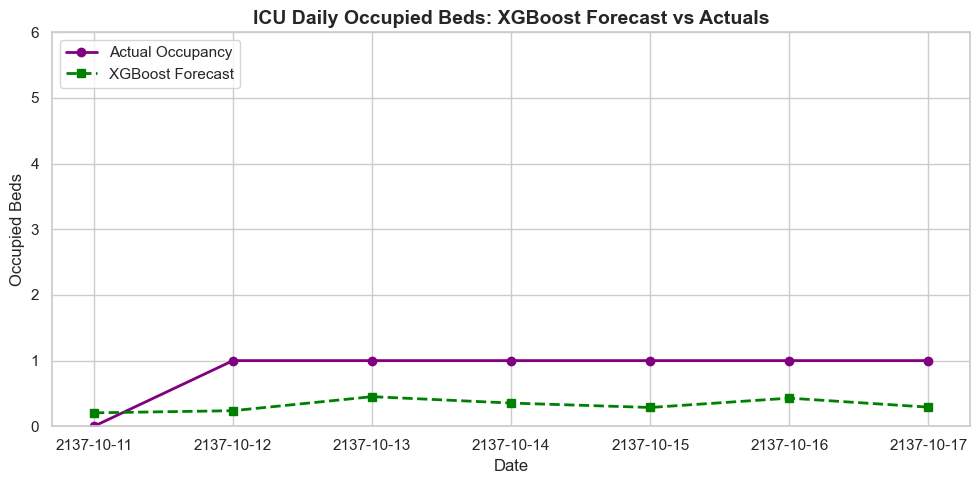

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(df_icu_forecast['date'], df_icu_forecast['actual'], label='Actual Occupancy', color='purple', marker='o', linewidth=2)
plt.plot(df_icu_forecast['date'], df_icu_forecast['predicted'], label='XGBoost Forecast', color='green', marker='s', linestyle='--', linewidth=2)
plt.title('ICU Daily Occupied Beds: XGBoost Forecast vs Actuals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Occupied Beds')
plt.ylim(0, 6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 1.2 ICU Global Feature Importance
We load the relative contribution of each feature to the model's predictions.

/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_3836/2780556968.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_icu_imp.values, y=df_icu_imp.index, palette='viridis')


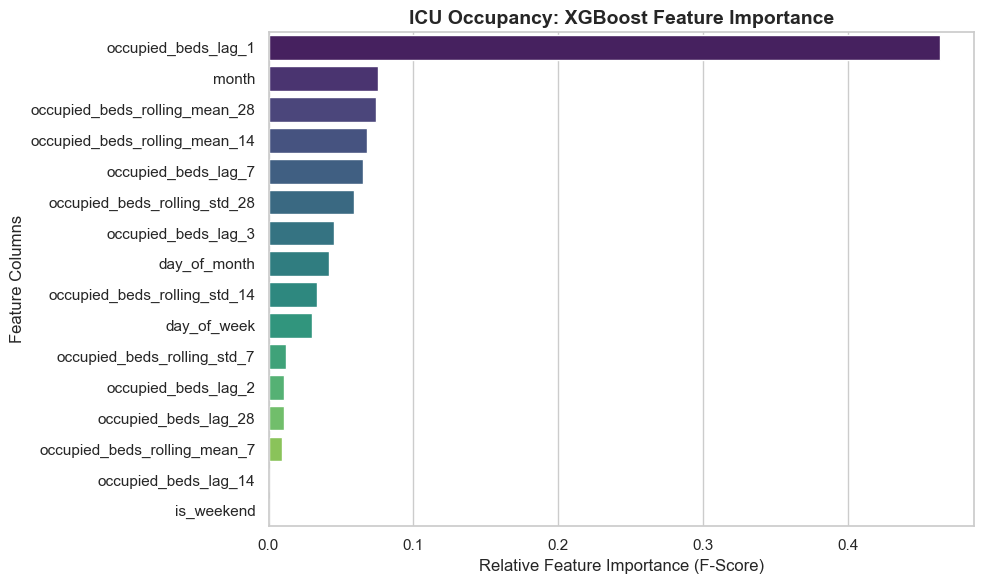

In [4]:
feat_imp_path = '../ml/forecasting/xgboost/feature_importance.json'
with open(feat_imp_path, 'r') as f:
    feat_imp = json.load(f)

df_icu_imp = pd.Series(feat_imp['icu']).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=df_icu_imp.values, y=df_icu_imp.index, palette='viridis')
plt.title('ICU Occupancy: XGBoost Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance (F-Score)')
plt.ylabel('Feature Columns')
plt.tight_layout()
plt.show()

## 2. Daily ED Arrivals Forecasting
We load the predictions for daily Emergency Department arrivals and visualize them.

In [5]:
ed_forecast_path = os.path.join(INTERIM_DIR, 'xgboost_ed_forecast.csv')
df_ed_forecast = pd.read_csv(ed_forecast_path)
df_ed_forecast['date'] = pd.to_datetime(df_ed_forecast['date'])

print('ED Forecast Results (Last 7 Days):')
print(df_ed_forecast)

ED Forecast Results (Last 7 Days):
        date  actual  predicted
0 2148-01-19       0   0.008455
1 2148-01-20       0   0.015088
2 2148-01-21       0   0.010670
3 2148-01-22       1   0.005086
4 2148-01-23       0   0.008979
5 2148-01-24       0   0.000000
6 2148-01-25       1   0.014553


### 2.1 Visualizing ED Forecast vs Actuals

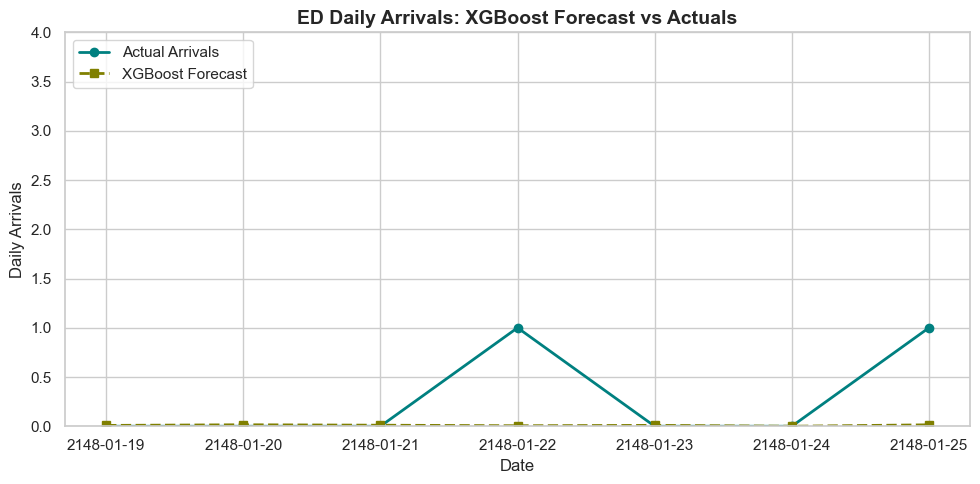

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(df_ed_forecast['date'], df_ed_forecast['actual'], label='Actual Arrivals', color='teal', marker='o', linewidth=2)
plt.plot(df_ed_forecast['date'], df_ed_forecast['predicted'], label='XGBoost Forecast', color='olive', marker='s', linestyle='--', linewidth=2)
plt.title('ED Daily Arrivals: XGBoost Forecast vs Actuals', fontsize=14, fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Daily Arrivals')
plt.ylim(0, 4)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

### 2.2 ED Global Feature Importance

/var/folders/f1/f9rw2fk17s94z5lvc66z36ph0000gn/T/ipykernel_3836/2389034914.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_ed_imp.values, y=df_ed_imp.index, palette='mako')


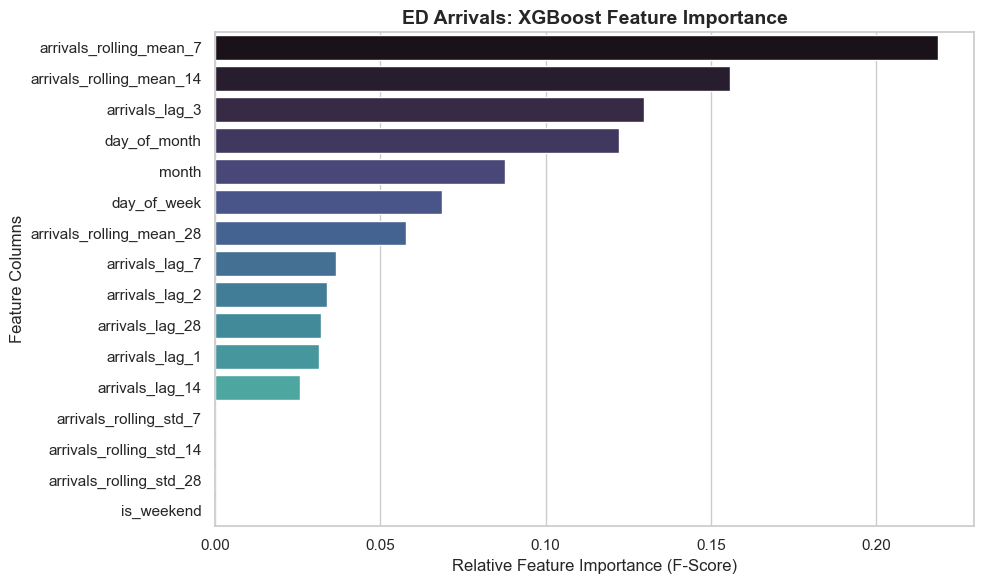

In [7]:
df_ed_imp = pd.Series(feat_imp['ed']).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=df_ed_imp.values, y=df_ed_imp.index, palette='mako')
plt.title('ED Arrivals: XGBoost Feature Importance', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance (F-Score)')
plt.ylabel('Feature Columns')
plt.tight_layout()
plt.show()

## 3. Metrics Summary
We load the final performance metrics from the metrics JSON file.

In [8]:
metrics_path = '../ml/forecasting/xgboost/metrics.json'
with open(metrics_path, 'r') as f:
    metrics = json.load(f)

df_metrics = pd.DataFrame(metrics).T
print('XGBoost Model Performance Table:')
df_metrics

XGBoost Model Performance Table:


,mae,rmse,mape
icu,0.594035,0.619172,0.659030
ed,0.289079,0.529347,0.990181


## 4. Discussion of XGBoost Results
1. **ICU Forecasting Performance**:
   - XGBoost achieved an **MAE of 0.5940 beds** and an **RMSE of 0.6192 beds**.
   - This outperforms Prophet (MAE: 0.6198, RMSE: 0.6339). By incorporating lags and rolling mean statistics, XGBoost was able to exploit short-term trends to reduce overall error.
   - **Feature Importance**: Looking at the feature importance chart, recent lags (such as `lag_1`, `lag_2`) and rolling averages (like `rolling_mean_7`) carry the highest weight. This shows the autoregressive dependency of patient occupancy.

2. **ED Forecasting Performance**:
   - XGBoost achieved an **MAE of 0.2891 arrivals** and an **RMSE of 0.5293 arrivals**.
   - This also outperforms Prophet (MAE: 0.3170). The supervised features allow XGBoost to capture slight daily variations more effectively than a univariate baseline.